## Preambule

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import os
import sys

In [2]:
sys.path.append(os.path.abspath("../../../src/effortsharing"))

## Read data

In [3]:
xr_dataread = xr.open_dataset("../../../data/output/startyear_2021/xr_dataread.nc")

## Add functions

In [4]:
from effortsharing.allocation_discontinuous.allocation_combinedapproaches import allocation_comb

allocator = allocation_comb()
allocator.ecpc()
allocator.pc()
allocator.discounting_historical_emissions()
allocator.approach1gdp()
allocator.approach1hdi()
allocator.approach2()
allocator.approach2_transition()
allocator.combine()
allocator.determine_tempoutcomes_discrete()
allocator.save()

## Compute negative emissions

In [8]:
CO2_neg = xr_dataread.CO2_neg_C
A1_neg = allocator.A1_neg.sel(Scenario='SSP2', Category='C1+C2')
A2_neg = allocator.A2_neg.sel(Scenario='SSP2', Category='C1+C2', Discount_factor=0, Historical_startyear=1950).GHG_hist_excl
A2_debts = allocator.A2_debts.sel(Scenario='SSP2', Category='C1+C2', Discount_factor=0, Historical_startyear=1950).GHG_hist_excl

In [ ]:
xr_dataread.sel(Region='BDI', Scenario='SSP2', Time=2050).Population.values

In [ ]:
plt.plot(A2_debts.Time, A2_debts.sel(Region='BDI'))
plt.plot(A2_debts.Time, A2_debts.sel(Region='NLD'))

## Plot

In [38]:
regions = ['USA', 'NLD', 'EU', 'RUS', 'CHN', 'BRA', 'IDN', 'IND', 'BDI', 'YEM']

In [ ]:
# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax_i, ax in enumerate([ax1, ax2]):
    A = [A1_neg, A2_neg][ax_i]
    x = A.Time.values
    groups = [np.array(A.sel(Region=reg).values) for reg in regions]

    ax.stackplot(x, groups, labels=regions)
    ax.set_xlabel("Time")
    ax.set_title(["Capability-based", "Responsibility-based"][ax_i])
    ax.plot(CO2_neg.Time, CO2_neg.sel(Category='C1+C2'), color='k', linestyle='--', label='Global')
    ax.set_xlim([2020, 2100])
ax1.legend(loc='upper left')
ax1.set_ylabel("Negative emissions")
fig.tight_layout()
plt.show()

In [ ]:
YEAR = 2050
pop = xr_dataread.Population.sel(Time=YEAR, Scenario='SSP2')

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax_i, ax in enumerate([ax1, ax2]):
    A = [A1_neg, A2_neg][ax_i]
    vals_2050 = [float(A.sel(Region=reg, Time=YEAR)/pop.sel(Region=reg)) for reg in regions]

    ax.bar(regions, vals_2050)
    ax.set_title(["Capability-based", "Responsibility-based"][ax_i])
    ax.plot(regions, len(regions)*[CO2_neg.sel(Category='C1+C2', Time=YEAR)/pop.sel(Region='EARTH')], color='k', linestyle='--', label='Global per capita')
ax1.set_ylabel("Negative emissions in "+str(YEAR)+", per capita")
plt.tight_layout()
plt.show()


## About historical emissions

In [46]:
ghg_incl = xr_dataread.GHG_hist
co2_excl = xr_dataread.CO2_hist_excl

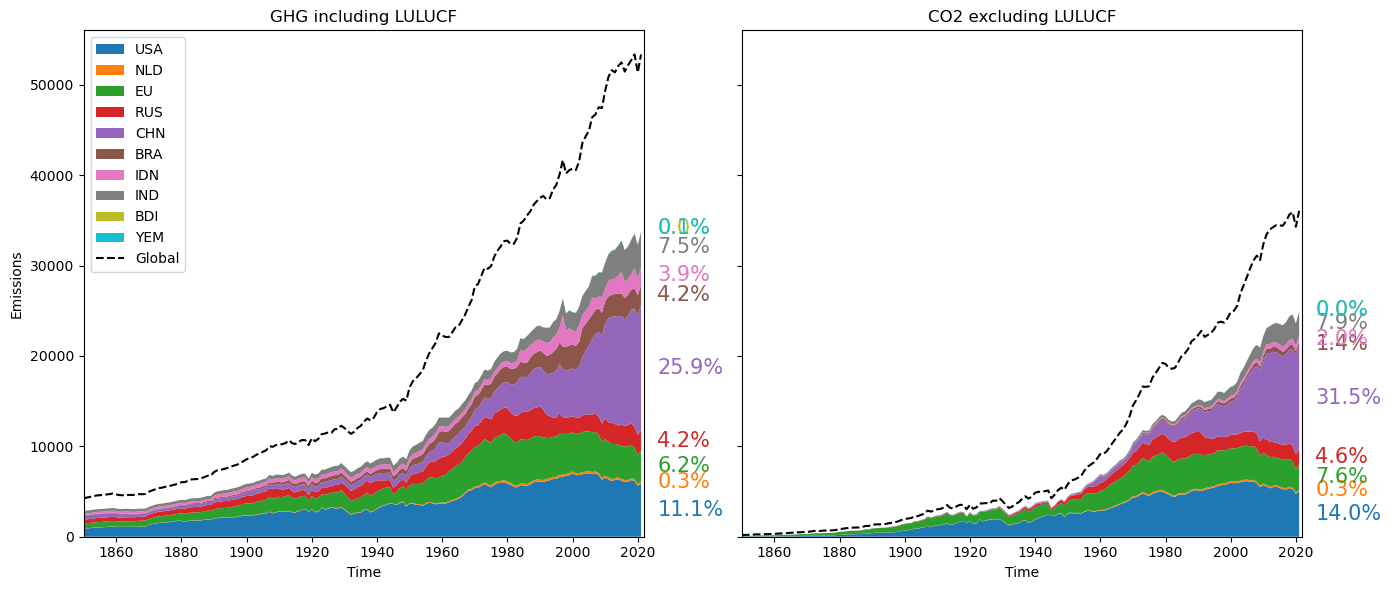

In [98]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax_i, ax in enumerate([ax1, ax2]):
    A = [ghg_incl, co2_excl][ax_i]
    x = A.Time.sel(Time=np.arange(1850, 2022)).values
    groups = [np.array(A.sel(Region=reg, Time=np.arange(1850, 2022)).values) for reg in regions]
    vals = np.vstack([A.sel(Region=r, Time=np.arange(1850, 2022)).values for r in regions])  # (R, T)

    ax.stackplot(x, groups, labels=regions)
    ax.set_xlabel("Time")
    ax.set_title(["GHG including LULUCF", "CO2 excluding LULUCF"][ax_i])
    glob = A.sel(Region='EARTH', Time=np.arange(1850, 2022))
    ax.plot(x, glob, color='k', linestyle='--', label='Global')
    ax.set_xlim([x.min(), 2022])

    # ---- Compute final-year stack top boundaries ----
    # Boundaries for each layer at the last timestep:
    boundaries = vals[:, -1]             # (R,)
    bottoms     = np.r_[0, boundaries[:-1]]        # lower edge of each layer
    tops        = boundaries                       # upper edge of each layer

    final_global = float(boundaries[-1])

    # Colors from the stackplot artists (1 per region)
    polys = ax.collections[-len(regions):]

    height_prev = 0
    for reg, bottom, top, poly in zip(regions, bottoms, tops, polys):
        height_top = height_prev + A.sel(Region=reg, Time=2022)                # vertical middle of band
        pct = 100 * A.sel(Region=reg, Time=2022) / A.sel(Region='EARTH', Time=2022)
        color = poly.get_facecolor()[0]

        ax.text(
            x[-1]+5,                           # nudge to right
            (height_top + height_prev)/2,                                # vertically centered
            f"{pct:.1f}%",
            va='center',
            color=color,
            fontsize=15
        )
        height_prev = height_top.copy()
ax1.legend(loc='upper left')
ax1.set_ylabel("Emissions")
fig.tight_layout()
plt.show()

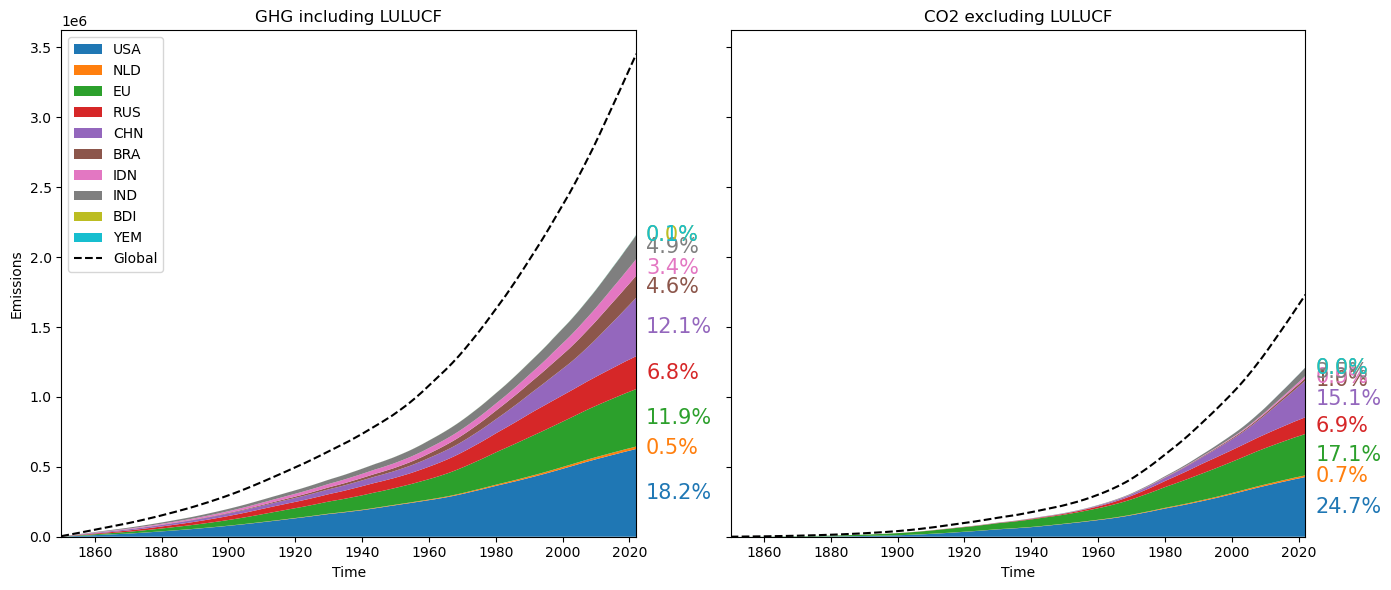

In [102]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax_i, ax in enumerate([ax1, ax2]):
    A = [ghg_incl, co2_excl][ax_i]
    x = A.Time.values
    groups = [np.array(A.sel(Region=reg).cumsum(dim="Time").values) for reg in regions]
    vals = np.vstack([A.sel(Region=r).cumsum(dim="Time").values for r in regions])  # (R, T)

    ax.stackplot(x, groups, labels=regions)
    ax.set_xlabel("Time")
    ax.set_title(["GHG including LULUCF", "CO2 excluding LULUCF"][ax_i])
    glob = A.sel(Region='EARTH').cumsum(dim="Time")
    ax.plot(x, A.sel(Region='EARTH').cumsum(dim="Time"), color='k', linestyle='--', label='Global')
    ax.set_xlim([x.min(), 2022])

    # ---- Compute final-year stack top boundaries ----
    # Boundaries for each layer at the last timestep:
    boundaries = vals[:, -1].cumsum()              # (R,)
    bottoms     = np.r_[0, boundaries[:-1]]        # lower edge of each layer
    tops        = boundaries                       # upper edge of each layer

    final_global = float(boundaries[-1])

    # Colors from the stackplot artists (1 per region)
    polys = ax.collections[-len(regions):]

    height_prev = 0
    for reg, bottom, top, poly in zip(regions, bottoms, tops, polys):
        height_top = height_prev + A.sel(Region=reg).cumsum(dim='Time').sel(Time=2100)                # vertical middle of band
        pct = 100 * A.sel(Region=reg).cumsum(dim='Time').sel(Time=2100) / A.sel(Region='EARTH').cumsum(dim='Time').sel(Time=2100)
        color = poly.get_facecolor()[0]

        ax.text(
            x[-1]-75,                           # nudge to right
            (height_top + height_prev)/2,                                # vertically centered
            f"{pct:.1f}%",
            va='center',
            color=color,
            fontsize=15
        )
        height_prev = height_top.copy()
ax1.legend(loc='upper left')
ax1.set_ylabel("Emissions")
fig.tight_layout()
plt.show()

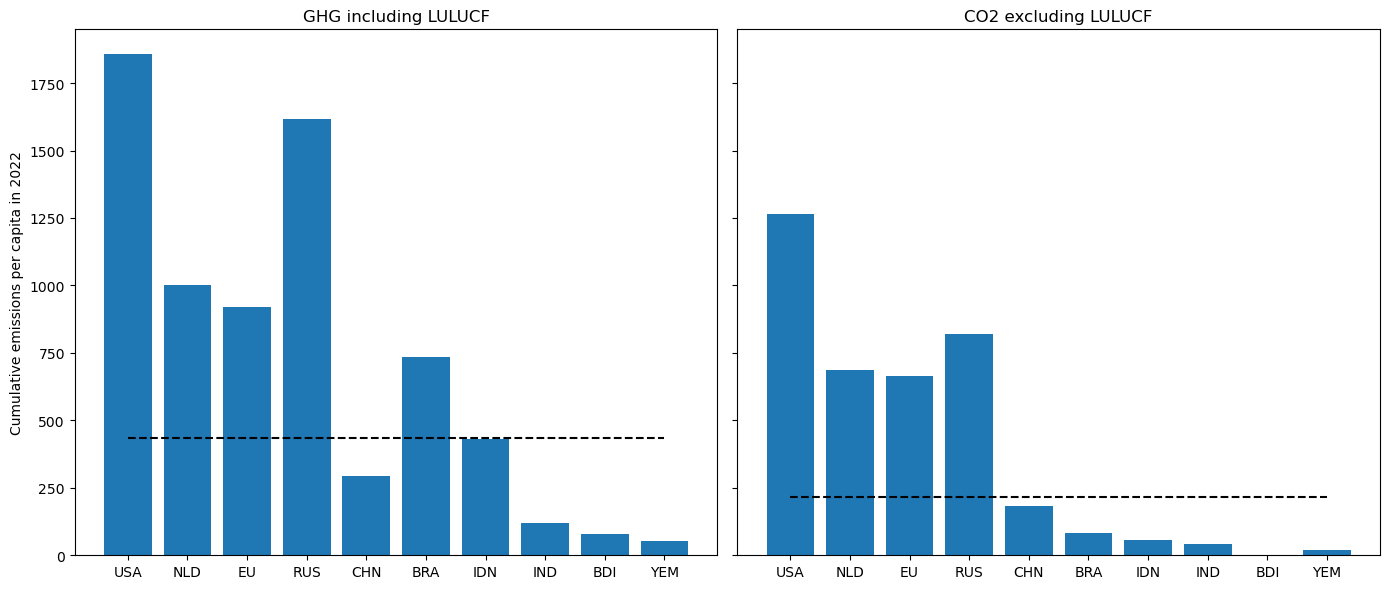

In [109]:
YEAR = 2022
pop = xr_dataread.Population.sel(Time=YEAR, Scenario='SSP2')

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

for ax_i, ax in enumerate([ax1, ax2]):
    A = [ghg_incl.cumsum(dim='Time'), co2_excl.cumsum(dim='Time')][ax_i]
    vals_year = [float(A.sel(Region=reg, Time=YEAR)/pop.sel(Region=reg)) for reg in regions]

    ax.bar(regions, vals_year)
    ax.set_title(["GHG including LULUCF", "CO2 excluding LULUCF"][ax_i])
    ax.plot(regions, len(regions)*[A.sel(Region='EARTH', Time=YEAR)/pop.sel(Region='EARTH')], color='k', linestyle='--', label='Global per capita')
ax1.set_ylabel("Cumulative emissions per capita in 2022")
plt.tight_layout()
plt.show()